In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones planificadas (semanas) y presupuesto por actividad (BAC, k€) se adjunta; el coste planificado de cada actividad se reparte uniformemente en su duración. Al final de la semana 10 se realiza un punto de control.

In [3]:
#| tbl-cap: "Planificación del proyecto"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, BAC
    ('A'     , '---'      , 6       , 10 ),
    ('B'     , '---'      , 7       , 50 ),
    ('C'     , '---'      , 7       , 20 ),
    ('D'     , 'A'        , 3       , 40 ),
    ('E'     , 'B,C'      , 2       , 50 ),
    ('F'     , 'C'        , 1       , 10 ),
    ('G'     , 'C'        , 1       , 40 ),
    ('H'     , 'D,E,G'    , 6       , 30 ),
    ('I'     , 'F,H'      , 6       , 60 ),
], columns=['activity', 'predecessor', 'duration', 'BAC']).set_index('activity')
datos_enunciado

,predecessor,duration,BAC
activity,,,
A,---,6,10
B,---,7,50
C,---,7,20
D,A,3,40
E,"B,C",2,50
F,C,1,10
G,C,1,40
H,"D,E,G",6,30
I,"F,H",6,60


In [4]:
#| tbl-cap: "Datos del punto de control (final de la semana 10)"
#| label: tbl-seguimiento
seguimiento = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 4              , 11, 100      ),
    ('B'     , 4              , 60, 100      ),
    ('C'     , 4              , 26, 100      ),
    ('D'     , 3              , 44, 100      ),
    ('E'     , 2              , 65, 100      ),
    ('F'     , 1              , 15, 100      ),
    ('G'     , 1              , 44, 100      ),
    ('H'     , 3              , 25, 75       ),
    ('I'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento

,actual_duration,AC,performed
activity,,,
A,4,11,100
B,4,60,100
C,4,26,100
D,3,44,100
E,2,65,100
F,1,15,100
G,1,44,100
H,3,25,75
I,0,0,0


In [5]:
pregunta_1 = "1. Calcule PV, EV y AC en el punto de control, y los índices CPI y SPI.  "
pregunta_2 = "2. El director informa al comité de que «vamos adelantados». ¿Es correcta la lectura? ¿Qué parte de la situación oculta?  "
pregunta_3 = "3. ¿Qué actividades explican el sobrecoste? Compare, actividad por actividad, el coste real con el valor ganado.  "
pregunta_4 = "4. Estime el coste final (EAC = BAC/CPI) y la variación al final (VAC). ¿Compensa el adelanto el sobrecoste? ¿Con qué dato del contrato lo decidiría?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule PV, EV y AC en el punto de control, y los índices CPI y SPI.  

2. El director informa al comité de que «vamos adelantados». ¿Es correcta la lectura? ¿Qué parte de la situación oculta?  

3. ¿Qué actividades explican el sobrecoste? Compare, actividad por actividad, el coste real con el valor ganado.  

4. Estime el coste final (EAC = BAC/CPI) y la variación al final (VAC). ¿Compensa el adelanto el sobrecoste? ¿Con qué dato del contrato lo decidiría?  

# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
BAC_total = float(datos_proyecto['BAC'].sum())
duracion_planificada = proyecto.duration(datos_proyecto['duration'])
semana_control = 10
datos_valor_ganado = pd.concat([datos_proyecto, seguimiento], axis=1)
gantts = EarnedValue(proyecto).calcula_gantts(datos_valor_ganado, planned_durations_label='duration',
                                             actual_durations_label='actual_duration', PV_label='BAC', AC_label='AC',
                                             percentage_complete_label='performed', tikz=True)

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Calcule PV, EV y AC en el punto de control, y los índices CPI y SPI.  

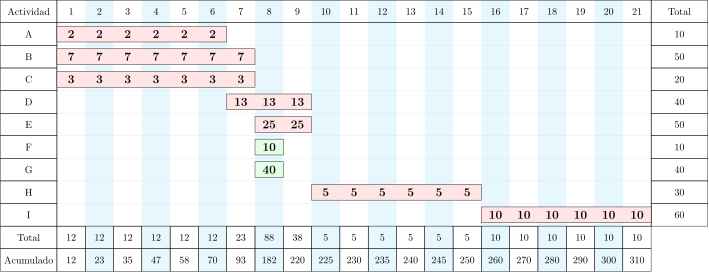

In [8]:
#| fig-cap: "PV: valor planificado"
#| label: fig-ganttPV
pinta_tikz(gantts['gantt_PV'])

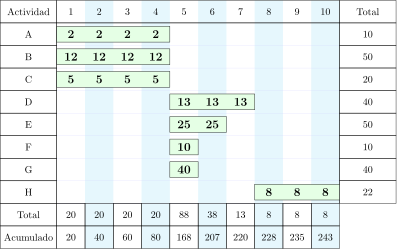

In [9]:
#| fig-cap: "EV: valor ganado"
#| label: fig-ganttEV
pinta_tikz(gantts['gantt_EV'])

In [10]:
acumulados = gantts['acumulados']
PV = float(acumulados.loc[semana_control, 'PV'])
EV = float((datos_valor_ganado['BAC'] * datos_valor_ganado['performed'] / 100).sum())
AC = float(datos_valor_ganado['AC'].sum())
CPI, SPI = EV / AC, EV / PV
pd.Series({'PV': PV, 'EV': EV, 'AC': AC, 'CV = EV − AC': EV - AC, 'SV = EV − PV': EV - PV, 'CPI': CPI, 'SPI': SPI}).round(3).to_frame('valor').T

,PV,EV,AC,CV = EV − AC,SV = EV − PV,CPI,SPI
valor,225.0,242.5,290.0,-47.5,17.5,0.836,1.078


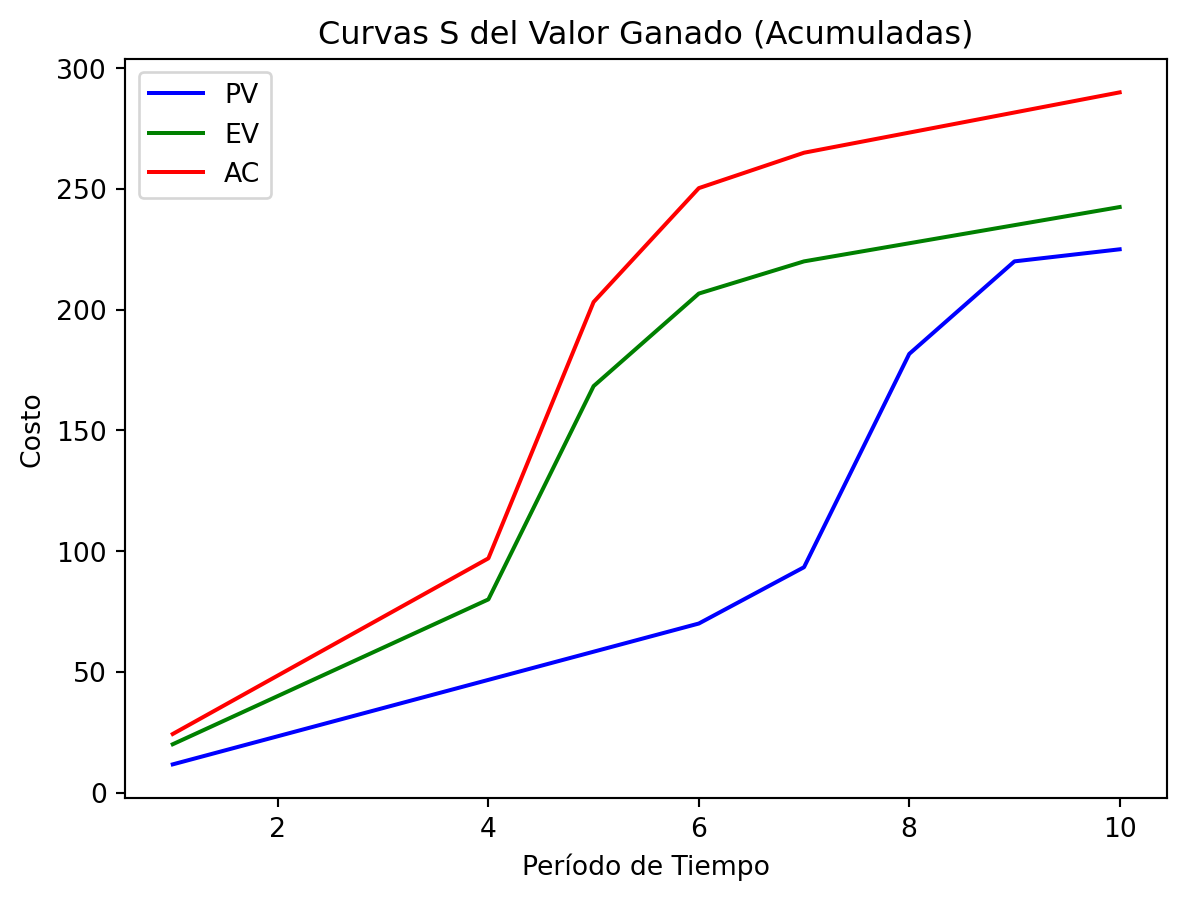

In [11]:
#| fig-cap: "Curvas S"
#| label: fig-curvasS
plot_curvas_valor_ganado(gantts)

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. El director informa al comité de que «vamos adelantados». ¿Es correcta la lectura? ¿Qué parte de la situación oculta?  

In [13]:
Markdown(f'''El adelanto es real (SPI = {SPI:.2f} ≥ 1: se ha ganado valor por {EV:.0f} frente a {PV:.0f} previstos), pero ha costado {AC:.0f}: CPI = {CPI:.2f} < 1, cada euro gastado rinde {CPI:.2f}. La lectura del director oculta el sobrecoste, que es lo que determinará si el proyecto acaba en presupuesto.''')

El adelanto es real (SPI = 1.08 ≥ 1: se ha ganado valor por 242 frente a 225 previstos), pero ha costado 290: CPI = 0.84 < 1, cada euro gastado rinde 0.84. La lectura del director oculta el sobrecoste, que es lo que determinará si el proyecto acaba en presupuesto.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. ¿Qué actividades explican el sobrecoste? Compare, actividad por actividad, el coste real con el valor ganado.  

In [15]:
por_actividad = datos_valor_ganado[['BAC', 'performed', 'AC']].copy()
por_actividad['EV'] = por_actividad['BAC'] * por_actividad['performed'] / 100
calendario = proyecto.calendar(datos_proyecto['duration'])
frac_planificada = ((semana_control - calendario['inicio_mas_temprano']).clip(lower=0).clip(upper=calendario['duracion']) / calendario['duracion'])
por_actividad['PV'] = por_actividad['BAC'] * frac_planificada
por_actividad['SV'] = por_actividad['EV'] - por_actividad['PV']
por_actividad['CV'] = por_actividad['EV'] - por_actividad['AC']
por_actividad.round(1)

,BAC,performed,AC,EV,PV,SV,CV
activity,,,,,,,
A,10,100,11,10.0,10.0,0.0,-1.0
B,50,100,60,50.0,50.0,0.0,-10.0
C,20,100,26,20.0,20.0,0.0,-6.0
D,40,100,44,40.0,40.0,0.0,-4.0
E,50,100,65,50.0,50.0,0.0,-15.0
F,10,100,15,10.0,10.0,0.0,-5.0
G,40,100,44,40.0,40.0,0.0,-4.0
H,30,75,25,22.5,5.0,17.5,-2.5
I,60,0,0,0.0,0.0,0.0,0.0


In [16]:
caras = por_actividad[por_actividad['CV'] < -0.5].sort_values('CV')
Markdown(f'Las actividades con CV negativa explican el sobrecoste: {", ".join(caras.index)}; las de mayor peso son {", ".join(caras.index[:2])}.')

Las actividades con CV negativa explican el sobrecoste: E, B, C, F, G, D, H, A; las de mayor peso son E, B.

## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. Estime el coste final (EAC = BAC/CPI) y la variación al final (VAC). ¿Compensa el adelanto el sobrecoste? ¿Con qué dato del contrato lo decidiría?  

In [18]:
EAC = BAC_total / CPI
VAC = BAC_total - EAC
Markdown(f'''EAC = {BAC_total:.0f} / {CPI:.2f} = {EAC:.0f} k€, VAC = {VAC:.0f} k€ (sobrecoste previsto). Que el adelanto compense depende de lo que valga el tiempo en el contrato: una prima por entrega anticipada o una penalización evitada por semana. Si la prima por semana adelantada multiplicada por las semanas que se ganarían supera {-VAC:.0f} k€, compensa; si no, se está comprando tiempo demasiado caro.''')

EAC = 310 / 0.84 = 371 k€, VAC = -61 k€ (sobrecoste previsto). Que el adelanto compense depende de lo que valga el tiempo en el contrato: una prima por entrega anticipada o una penalización evitada por semana. Si la prima por semana adelantada multiplicada por las semanas que se ganarían supera 61 k€, compensa; si no, se está comprando tiempo demasiado caro.